In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import seaborn as sns

In [2]:
import data                       

In [3]:
plt.style.use("../../nice.mplstyle")

In [4]:
fig_dir = "runs/v3/figures"
if not os.path.isdir(fig_dir):
    os.makedirs(fig_dir)

In [5]:
ads = xr.open_dataset("runs/v3/metrics/sla.all_groups.nc", chunks="auto")
ads = ads.squeeze()
ads.load();

In [6]:
spec = data.normalise_spec({"observed_as": "sla_filtered", "groups": "auto", "count": "obs_count_{group}"})
sds = data.pooled_statistics(spec)

In [7]:
sds

<xarray.Dataset> Size: 40B
Dimensions:  ()
Data variables:
    mean     float64 8B 0.03854
    stdev    float64 8B 0.08641
    minimum  float64 8B -1.318
    maximum  float64 8B 1.342
    count    float64 8B 6.283e+07
Attributes:
    description:            statistics pooled over every group observing sla_...
    groups:                 ['cryosat_2', 'envisat', 'envisat_new_orbit', 'er...
    statistics_start_date:  2000-01-01T12:00:00
    statistics_end_date:    2014-12-31T12:00:00

In [8]:
def histplot(metric, show_stdev=False):
    
    fig, axs = plt.subplots(1, 2, figsize=(12,5))
    
    ax = axs[0]
    for varname, label in zip(
        [metric, f"{metric}_pooled"],
        ["Raw Mean", "$N_{obs}$ Weighted"],
    ):
        sns.histplot(
            ads[varname],
            ax=ax,
            label=label,
        )

    if show_stdev:
        ax.axvline(x=sds["stdev"], color="gray", label="Pooled Training Std. Dev.")
    ax.legend()
    
    ax = axs[1]
    for varname in [
        "n_obs",
    ]:
        ads[varname].plot(ax=ax, label=varname, color="C3")
        ax.set(title="")
        ax.legend()
        

    return fig, axs

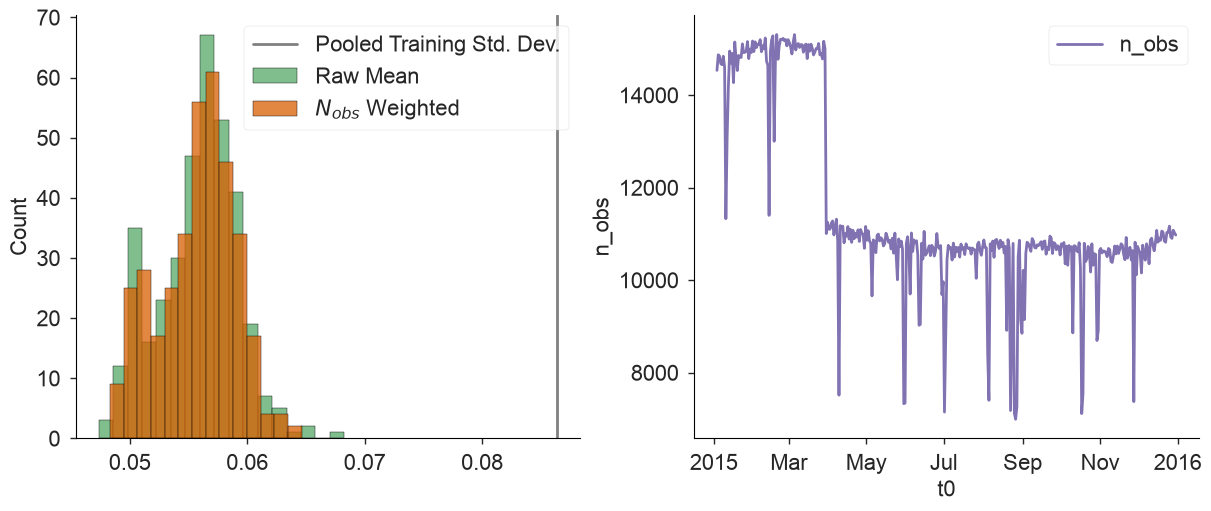

In [9]:
histplot("rmse", show_stdev=True);

(<Figure size 1200x500 with 2 Axes>,
 array([<Axes: ylabel='Count'>, <Axes: xlabel='t0', ylabel='n_obs'>],
       dtype=object))

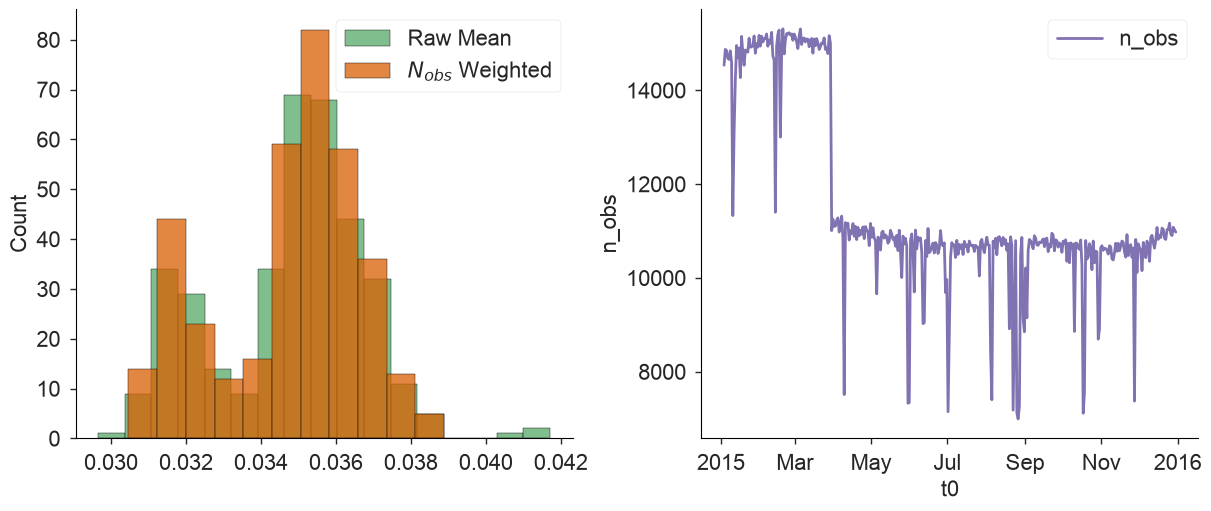

In [10]:
histplot("mae")